# 01 · Baselines: LightGBM & CatBoost

First end-to-end models: **no extra feature engineering**, just the modeling table from `processing/03_build_model_table.ipynb`, fed to two gradient-boosting libraries with the **same protocol and the same tests**.

| Step | What happens (for each model) |
|---|---|
| 1. Data | Load `model_table.parquet`; features = everything except IDs, the target, the raw date and the two ZIP strings |
| 2. Tune rounds | 5-fold stratified CV on **train** picks the number of trees (early stopping on AUC) |
| 3. Validate | Fit on train, score **valid**: AUC, top-decile precision, decile lift, calibration, importance |
| 4. Compare | Side-by-side metrics and charts; correlation between the two models' predictions |
| 5. Submit | Re-pick rounds with CV on **train + valid**, refit on all labeled data, predict **holdout** → one CSV per model in `submissions/` |

The valid set is never used to choose anything, so its scores are honest estimates. EDA reference: a default LightGBM reached 0.690 CV AUC.

**Why both?**
- LightGBM splits categoricals natively and is fast.
- CatBoost uses ordered target statistics for categoricals and symmetric trees. It's often stronger on small tabular data, and its errors differ from LightGBM's, which matters for an ensemble later.

In [1]:
import tempfile
from datetime import date
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb, catboost as cb
from sklearn.metrics import roc_auc_score

df = pd.read_parquet('../data/processed/model_table.parquet')
FEATS = df.columns.drop(['POLICY_ID', 'SPLIT', 'CONVERT_IND', 'QUOTE_DT', 'ZIP_CD', 'ZIP3']).tolist()
CATS = df[FEATS].select_dtypes('category').columns.tolist()
train, valid, hold = (df[df.SPLIT == s] for s in ('train', 'valid', 'holdout'))
labeled = pd.concat([train, valid])
print(f'{len(FEATS)} features ({len(CATS)} categorical: {CATS}) | train {len(train):,} | valid {len(valid):,} | holdout {len(hold):,}')

77 features (5 categorical: ['STATE_CD', 'PRIOR_CARRIER_GRP', 'COV_PKG_TYPE', 'PRIMARY_PARKING', 'QUOTE_CHANNEL']) | train 22,122 | valid 7,374 | holdout 7,375


## 1. Shared evaluation
`evaluate` computes the competition metrics on valid:
- **AUC-ROC** (primary).
- **Precision in the top decile**, the tie-break: the share of the 10% highest-scored quotes that converted.
- A **decile table** of observed rate, mean prediction, lift and cumulative share of conversions captured. It drives the lift chart and calibration plot.

In [2]:
yv = valid.CONVERT_IND

def evaluate(p):
    dec = pd.qcut(pd.Series(p, index=valid.index).rank(method='first'), 10, labels=range(10, 0, -1))  # 1 = highest scores
    t = pd.DataFrame({'pred': p, 'y': yv, 'decile': dec}).groupby('decile', observed=True).agg(
        quotes=('y', 'size'), converted=('y', 'sum'), observed=('y', 'mean'), predicted=('pred', 'mean')).sort_index(ascending=False)
    t['lift'] = t.observed / yv.mean()
    t['cum. capture'] = t.converted.cumsum() / t.converted.sum()
    return {'AUC': roc_auc_score(yv, p), 'top-decile precision': t.observed.iloc[0], 'top-decile lift': t.lift.iloc[0],
            'top-3-decile capture': t['cum. capture'].iloc[2]}, t

results, preds, tables, importances, rounds = {}, {}, {}, {}, {}

## 2. LightGBM
These are conservative, untuned defaults for ~22K rows at an 11% positive rate: small trees (15 leaves), learning rate 0.02, row/column subsampling 0.8, a minimum leaf size of 50 and L2 = 1. Categoricals use LightGBM's native handling (`category` dtype).

In [3]:
LGB_PARAMS = dict(objective='binary', metric='auc', learning_rate=0.02, num_leaves=15, min_child_samples=50,
                  feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbosity=-1, seed=42)

def lgb_rounds(data):
    """5-fold stratified CV with early stopping → (best number of trees, CV AUC)."""
    cv = lgb.cv(LGB_PARAMS, lgb.Dataset(data[FEATS], data.CONVERT_IND), num_boost_round=5000, nfold=5, stratified=True, seed=42,
                callbacks=[lgb.early_stopping(200, verbose=False)])
    return len(cv['valid auc-mean']), cv['valid auc-mean'][-1]

def lgb_fit(data, n):
    return lgb.train(LGB_PARAMS, lgb.Dataset(data[FEATS], data.CONVERT_IND), num_boost_round=n)

rounds['LightGBM'], cv_auc = lgb_rounds(train)
m = lgb_fit(train, rounds['LightGBM'])
preds['LightGBM'] = m.predict(valid[FEATS])
importances['LightGBM'] = pd.Series(m.feature_importance('gain'), FEATS)
results['LightGBM'], tables['LightGBM'] = evaluate(preds['LightGBM'])
results['LightGBM']['train CV AUC'] = cv_auc
print(f"LightGBM: {rounds['LightGBM']} trees | train CV AUC {cv_auc:.4f} | VALID AUC {results['LightGBM']['AUC']:.4f}")
tables['LightGBM'].round(3)

LightGBM: 276 trees | train CV AUC 0.6906 | VALID AUC 0.6890


,quotes,converted,observed,predicted,lift,cum. capture
decile,,,,,,
1,738,210.0,0.285,0.261,2.546,0.255
2,737,135.0,0.183,0.172,1.639,0.419
3,737,109.0,0.148,0.138,1.324,0.551
4,738,69.0,0.093,0.116,0.837,0.635
5,737,79.0,0.107,0.100,0.959,0.731
6,737,57.0,0.077,0.087,0.692,0.800
7,738,65.0,0.088,0.076,0.788,0.879
8,737,38.0,0.052,0.065,0.461,0.925
9,737,33.0,0.045,0.054,0.401,0.965


## 3. CatBoost
- **Input format:** CatBoost needs categoricals as strings and can't take pandas' nullable `Int8`, so `cb_X` casts categoricals to `str` and everything else to `float` (NaN stays NaN; CatBoost treats it as "below minimum"). The values are unchanged.
- **Parameters:** CatBoost's standard defaults (depth 6, L2 = 3) with learning rate 0.03, Logloss loss and AUC for early stopping. They aren't tuned.
- **Rounds:** `cb.cv` gives the 5-fold stratified CV curve, and the best iteration is where mean test AUC peaks.

In [4]:
CB_PARAMS = dict(loss_function='Logloss', eval_metric='AUC', learning_rate=0.03, depth=6, l2_leaf_reg=3,
                 random_seed=42, logging_level='Silent', allow_writing_files=False,
                 train_dir=f'{tempfile.gettempdir()}/catboost_info')  # cb.cv writes logs regardless; keep them out of the repo

def cb_X(data):
    return data[FEATS].astype({c: str for c in CATS} | {c: float for c in FEATS if c not in CATS})

def cb_pool(data):
    return cb.Pool(cb_X(data), data.CONVERT_IND, cat_features=CATS)

def cb_rounds(data):
    cv = cb.cv(cb_pool(data), CB_PARAMS | {'iterations': 5000}, fold_count=5, stratified=True, shuffle=True, seed=42,
               early_stopping_rounds=200)
    best = cv['test-AUC-mean'].idxmax()
    return int(best) + 1, cv['test-AUC-mean'][best]

def cb_fit(data, n):
    return cb.CatBoostClassifier(**CB_PARAMS, iterations=n).fit(cb_pool(data))

rounds['CatBoost'], cv_auc = cb_rounds(train)
m = cb_fit(train, rounds['CatBoost'])
preds['CatBoost'] = m.predict_proba(cb_X(valid))[:, 1]
importances['CatBoost'] = pd.Series(m.get_feature_importance(), FEATS)
results['CatBoost'], tables['CatBoost'] = evaluate(preds['CatBoost'])
results['CatBoost']['train CV AUC'] = cv_auc
print(f"CatBoost: {rounds['CatBoost']} trees | train CV AUC {cv_auc:.4f} | VALID AUC {results['CatBoost']['AUC']:.4f}")
tables['CatBoost'].round(3)

CatBoost: 422 trees | train CV AUC 0.6962 | VALID AUC 0.6940


,quotes,converted,observed,predicted,lift,cum. capture
decile,,,,,,
1,738,203.0,0.275,0.260,2.462,0.246
2,737,141.0,0.191,0.173,1.712,0.417
3,737,99.0,0.134,0.140,1.202,0.538
4,738,96.0,0.130,0.119,1.164,0.654
5,737,73.0,0.099,0.101,0.886,0.743
6,737,64.0,0.087,0.087,0.777,0.820
7,738,42.0,0.057,0.074,0.509,0.871
8,737,46.0,0.062,0.062,0.559,0.927
9,737,34.0,0.046,0.050,0.413,0.968


## 4. Comparison on valid
- **Metrics:** side by side for both models.
- **Correlation of predictions:** the lower the correlation, the more a blend of the two could gain.
- **Charts:**
  - **lift:** the two models as grouped bars per decile
  - **calibration:** one line per model against the diagonal
  - **importance:** each model's top 15, as a share of total. LightGBM uses split gain; CatBoost uses its default "PredictionValuesChange".

In [5]:
cmp = pd.DataFrame(results).T[['AUC', 'train CV AUC', 'top-decile precision', 'top-decile lift', 'top-3-decile capture']]
display(cmp.style.format({'AUC': '{:.4f}', 'train CV AUC': '{:.4f}', 'top-decile precision': '{:.1%}', 'top-decile lift': '{:.2f}×', 'top-3-decile capture': '{:.1%}'}))
r = np.corrcoef(preds['LightGBM'], preds['CatBoost'])[0, 1]
rs = pd.Series(preds['LightGBM']).corr(pd.Series(preds['CatBoost']), method='spearman')
print(f'prediction correlation: Pearson {r:.3f}, Spearman (rank) {rs:.3f}')

,AUC,train CV AUC,top-decile precision,top-decile lift,top-3-decile capture
LightGBM,0.6890,0.6906,28.5%,2.55×,55.1%
CatBoost,0.6940,0.6962,27.5%,2.46×,53.8%


prediction correlation: Pearson 0.934, Spearman (rank) 0.938


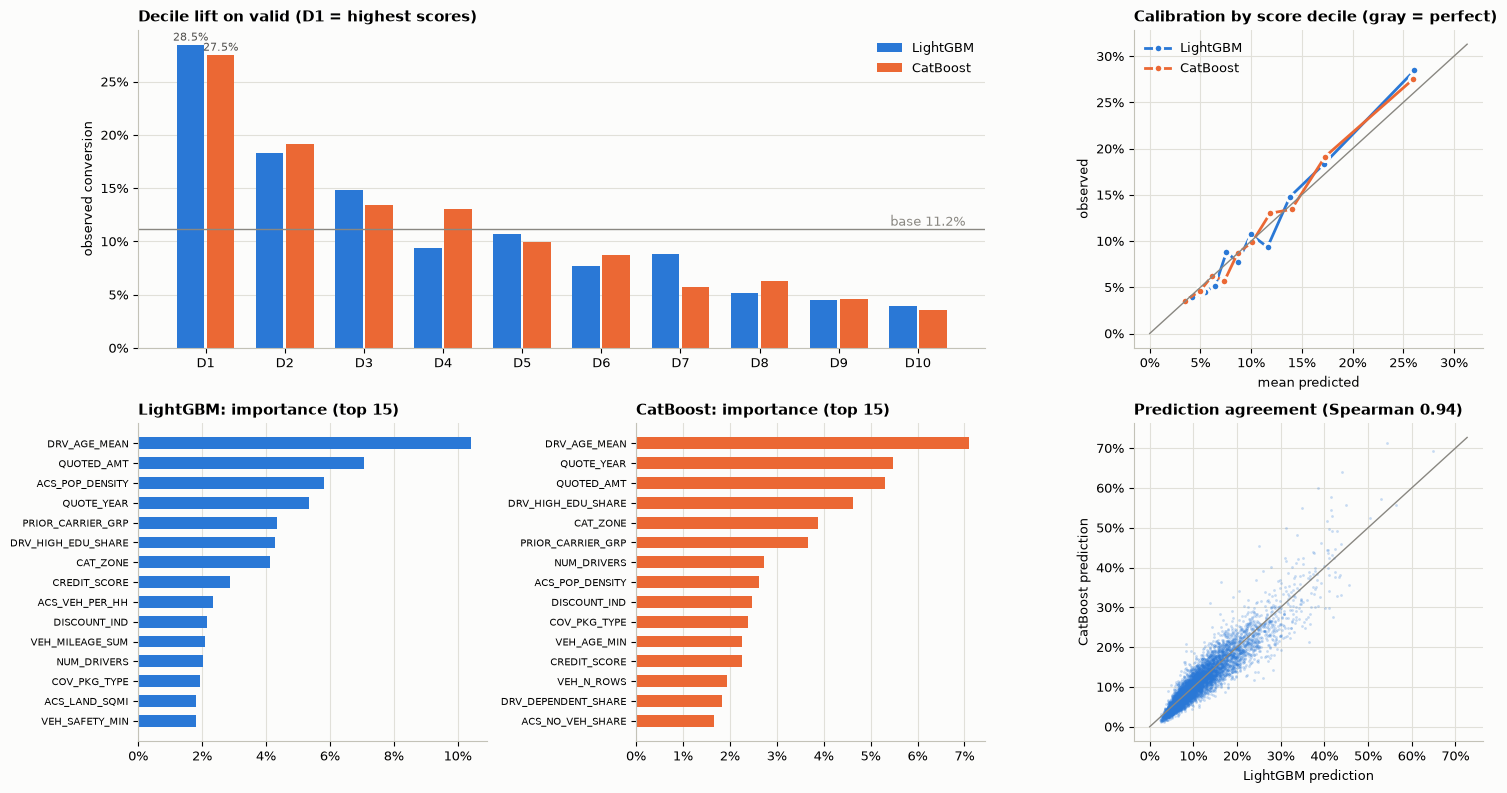

In [6]:
COLORS, MUTED, INK2, SURF = {'LightGBM': '#2a78d6', 'CatBoost': '#eb6834'}, '#898781', '#52514e', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'axes.axisbelow': True, 'axes.edgecolor': '#c3c2b7',
                     'axes.titlelocation': 'left', 'axes.titleweight': 'bold', 'legend.frameon': False, 'font.size': 9})
pct = plt.FuncFormatter(lambda v, _: f'{v:.0%}')
fig = plt.figure(figsize=(15, 8)); gs = fig.add_gridspec(2, 3)
a1, a2 = fig.add_subplot(gs[0, :2]), fig.add_subplot(gs[0, 2])

x, w = np.arange(1, 11), .38
for i, (name, t) in enumerate(tables.items()):
    a1.bar(x + (i - .5) * w, t.observed, width=w * .92, color=COLORS[name], label=name)
    a2.plot(t.predicted, t.observed, color=COLORS[name], lw=2, marker='o', ms=6, mec=SURF, mew=2, label=name)
a1.axhline(yv.mean(), color=MUTED, lw=1); a1.text(10.6, yv.mean() + .003, f'base {yv.mean():.1%}', ha='right', color=MUTED)
for name, t in tables.items():  # label only the top decile: the number the tie-break is about
    a1.text(1 + (list(tables).index(name) - .5) * w, t.observed.iloc[0] + .004, f'{t.observed.iloc[0]:.1%}', ha='center', fontsize=8, color=INK2)
a1.set_xticks(x, [f'D{i}' for i in x]); a1.yaxis.set_major_formatter(pct); a1.grid(axis='x', visible=False); a1.legend()
a1.set_title('Decile lift on valid (D1 = highest scores)'); a1.set_ylabel('observed conversion')
lim = max(t[['observed', 'predicted']].max().max() for t in tables.values()) * 1.1
a2.plot([0, lim], [0, lim], color=MUTED, lw=1); a2.legend(loc='upper left')
a2.xaxis.set_major_formatter(pct); a2.yaxis.set_major_formatter(pct); a2.set_xlabel('mean predicted'); a2.set_ylabel('observed')
a2.set_title('Calibration by score decile (gray = perfect)')

for j, (name, imp) in enumerate(importances.items()):
    a = fig.add_subplot(gs[1, j]); s = (imp / imp.sum()).nlargest(15)[::-1]
    a.barh(s.index, s, height=.6, color=COLORS[name]); a.xaxis.set_major_formatter(pct); a.grid(axis='y', visible=False)
    a.set_title(f'{name}: importance (top 15)'); a.tick_params(axis='y', labelsize=7.5)
a = fig.add_subplot(gs[1, 2])
a.scatter(preds['LightGBM'], preds['CatBoost'], s=4, alpha=.25, color=COLORS['LightGBM'], lw=0)
lo, hi = 0, max(map(max, preds.values())) * 1.02
a.plot([lo, hi], [lo, hi], color=MUTED, lw=1); a.xaxis.set_major_formatter(pct); a.yaxis.set_major_formatter(pct)
a.set_xlabel('LightGBM prediction'); a.set_ylabel('CatBoost prediction'); a.set_title(f'Prediction agreement (Spearman {rs:.2f})')
fig.tight_layout(); Path('figures').mkdir(exist_ok=True); fig.savefig('figures/01_baselines_valid.png', bbox_inches='tight')

**Findings on valid**

| | LightGBM | CatBoost |
|---|---|---|
| **Valid AUC** (primary) | 0.6890 | **0.6940** |
| Train CV AUC | 0.6906 | **0.6962** |
| **Top-decile precision** (tie-break) | **28.5%** (2.55×) | 27.5% (2.46×) |
| Top-3-decile capture | **55.1%** | 53.8% |

- **CatBoost is ahead on the primary metric by ~0.005 AUC**, both on valid and in CV, so the gap is consistent.
- **LightGBM's top decile is ~1 pp better.** At ~740 quotes per decile that's about 7 converters, well within noise.
- **Both are well calibrated.** CatBoost's points sit closer to the diagonal and its decile curve is smoother (no D4/D5 swap).
- **The models largely agree.** Rank correlation is 0.94, and both lean on average driver age, quoted amount, quote year, high-education share, CAT zone and prior carrier.
- **Where they differ:**
  - LightGBM leans more on Census density.
  - CatBoost spreads weight across `NUM_DRIVERS`, discount and coverage package.

  That difference means a blend may add a little, though with correlation this high the gain will be modest.

## 5. Refit on all labeled data → holdout submissions
For each model:
1. Re-choose the number of trees by 5-fold CV on **train + valid** (29.5K quotes).
2. Refit on that combined set and predict **holdout**.
3. Write `submissions/<model>_baseline_<date>.csv` in the `sample_submission.csv` format.

The checks confirm the column names, one row per holdout policy, unique IDs and probabilities in [0, 1].

In [7]:
final_preds, cv_all = {}, {}
n, cv_all['LightGBM'] = lgb_rounds(labeled)
final_preds['LightGBM'] = lgb_fit(labeled, n).predict(hold[FEATS])
n, cv_all['CatBoost'] = cb_rounds(labeled)
final_preds['CatBoost'] = cb_fit(labeled, n).predict_proba(cb_X(hold))[:, 1]

cols = pd.read_csv('../sample_submission.csv', nrows=0).columns.tolist()
for name, p in final_preds.items():
    sub = pd.DataFrame({'POLICY_ID': hold.POLICY_ID.values, 'CONVERT_IND_PRED': p})
    assert list(sub.columns) == cols and len(sub) == 7375 and sub.POLICY_ID.is_unique and sub.CONVERT_IND_PRED.between(0, 1).all()
    out = Path('../submissions') / f'{name.lower()}_baseline_{date.today():%Y%m%d}.csv'
    out.parent.mkdir(exist_ok=True); sub.to_csv(out, index=False)
    print(f'{name}: train+valid CV AUC {cv_all[name]:.4f} | wrote {out} | mean prediction {p.mean():.4f}')
print(f'holdout prediction rank correlation between models: {pd.Series(final_preds["LightGBM"]).corr(pd.Series(final_preds["CatBoost"]), method="spearman"):.3f}')

LightGBM: train+valid CV AUC 0.6944 | wrote ../submissions/lightgbm_baseline_20261030.csv | mean prediction 0.1109
CatBoost: train+valid CV AUC 0.7014 | wrote ../submissions/catboost_baseline_20261030.csv | mean prediction 0.1096
holdout prediction rank correlation between models: 0.946


**Submissions written**
- `catboost_baseline_<date>.csv`: train+valid CV AUC **0.701**. This is the stronger candidate for the first submission.
- `lightgbm_baseline_<date>.csv`: train+valid CV AUC 0.694.

Both have mean predictions close to the 11.2% base rate. Training on 33% more data adds ~0.004–0.005 CV AUC for both models.

**Next steps:**
- Optuna tuning for both models.
- Target encoding of `ZIP_CD` / `MAKE_MODEL` inside CV.
- Seed averaging.
- A rank-average blend of the two.